# Esteira de Aprendizado de Máquina — Classificação de Filmes

**Objetivo:** construir uma esteira completa de Machine Learning, desde a preparação dos dados até a avaliação e a predição com o modelo implantado.

**Base de dados:** [Movie Metadata: Genre, Crew, Color & Tech Specs](https://www.kaggle.com/datasets/danielaijdkx/movie-metadata-genre-crew-color-tech-specs/data) (Kaggle, Daniel Silalahi, licença CC0).

**Problema de classificação:** prever se um filme é **colorido** (`color`) ou **preto-e-branco** (`black-and-white`) a partir de metadados como ano de lançamento, duração, orçamento, bilheteria, avaliações, prêmios e quantidade de gêneros/diretores/idiomas. O rótulo original `color_type` é usado apenas para formar o alvo e é **removido dos preditores** (evita vazamento de informação).

### Etapas do notebook
1. Estatísticas descritivas gerais da base original.
2. Transformação nas **linhas** (limpeza/filtragem de registros).
3. Transformação nas **colunas** (engenharia de atributos e alvo binário).
4. Divisão em **treinamento**, **validação** e **teste**.
5. Treinamento do modelo com pipeline de pré-processamento.
6. Avaliação: **acurácia** e **matriz de confusão**.
7. **Predição com o modelo implantado** (serializado e recarregado).

## Configuração e carregamento da base

O notebook usa o arquivo `dados/movies.csv`. Se ele não existir, o código faz o download do ZIP público da base diretamente da API do Kaggle e extrai apenas a tabela principal de filmes.

In [1]:
import os
import zipfile
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)

print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | seed {SEED}')

pandas 3.0.6 | scikit-learn 1.9.1 | seed 42


In [2]:
DADOS_DIR = Path('dados')
CSV_PATH = DADOS_DIR / 'movies.csv'
URL_KAGGLE = ('https://www.kaggle.com/api/v1/datasets/download/'
              'danielaijdkx/movie-metadata-genre-crew-color-tech-specs?datasetVersionNumber=14')
URL_KAGGLE_SEM_VERSAO = ('https://www.kaggle.com/api/v1/datasets/download/'
                         'danielaijdkx/movie-metadata-genre-crew-color-tech-specs')

def baixar_com_curl(url, destino):
    subprocess.run(['curl', '-L', '--fail', '--silent', '--show-error',
                    '-o', str(destino), url], check=True, timeout=600)

if not CSV_PATH.exists():
    print('Arquivo local não encontrado. Baixando dataset do Kaggle...')
    DADOS_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = DADOS_DIR / 'movies_kaggle.zip'
    try:
        baixar_com_curl(URL_KAGGLE, zip_path)
    except Exception:
        try:
            baixar_com_curl(URL_KAGGLE_SEM_VERSAO, zip_path)
        except Exception as erro_download:
            try:
                from google.colab import files
            except ImportError:
                raise erro_download
            print('Download automático indisponível. Envie o arquivo movies.csv:')
            files.upload()
            Path('movies.csv').replace(CSV_PATH)
    if zip_path.exists() and zip_path.stat().st_size > 0:
        with zipfile.ZipFile(zip_path) as zf:
            zf.extract('movies.csv', DADOS_DIR)
    print('Download e extração concluídos.')
else:
    print(f'Usando arquivo local: {CSV_PATH.resolve()}')

df = pd.read_csv(CSV_PATH)
print(f'\nBase carregada: {df.shape[0]:,} linhas x {df.shape[1]} colunas')
df.head(3)

Arquivo local não encontrado. Baixando dataset do Kaggle...


Download e extração concluídos.

Base carregada: 26,545 linhas x 30 colunas


,film_id,title,original_title,release_date,release_year,runtime_min,color,color_type,aspect_ratio,aspect_ratio_value,genres,directors,countries,original_languages,mpa_rating,distribution_formats,production_companies,distributors,series,based_on,budget_usd,box_office_usd,rotten_tomatoes_pct,metacritic_score,oscar_wins,oscar_nominations,n_cast,wikipedia_languages,imdb_id,tmdb_id
0,Q1000394,This Modern Age,This Modern Age,1931-08-29,1931.0,69.0,black-and-white,black-and-white,NaN,NaN,drama film|romance film,Nick Grinde,United States,English,NaN,NaN,Metro-Goldwyn-Mayer,Metro-Goldwyn-Mayer,NaN,NaN,NaN,NaN,NaN,NaN,0,0,12,10,tt0022478,199030.0
1,Q1000826,Guns of the Magnificent Seven,Guns of the Magnificent Seven,1969-01-01,1969.0,100.0,color,color,NaN,NaN,Western film,Paul Wendkos,United States,English,NaN,video on demand,The Mirisch Company,Netflix|United Artists,NaN,NaN,NaN,NaN,NaN,NaN,0,0,12,14,tt0064395,12625.0
2,Q1001102,The Rat Savior,Izbavitelj,1976-10-26,1976.0,75.0,color,color,NaN,NaN,horror film|science fiction film,Krsto Papić,Socialist Federal Republic of Yugoslavia|Yugos...,Croatian|Serbian|Serbo-Croatian,NaN,NaN,Jadran Film,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,7,12,tt0074701,169250.0


## 1. Estatísticas descritivas gerais da base

Análise da base **original**, antes de qualquer transformação: dimensões, tipos, resumo estatístico de todas as colunas, percentual de valores ausentes e distribuição da variável de interesse.

In [3]:
print('Dimensões da base original:', df.shape)
print('\nTipos de dados:')
print(df.dtypes.to_string())
print('\nPrimeiras linhas:')
display(df.head())

Dimensões da base original: (26545, 30)

Tipos de dados:
film_id                     str
title                       str
original_title              str
release_date                str
release_year            float64
runtime_min             float64
color                       str
color_type                  str
aspect_ratio                str
aspect_ratio_value      float64
genres                      str
directors                   str
countries                   str
original_languages          str
mpa_rating                  str
distribution_formats        str
production_companies        str
distributors                str
series                      str
based_on                    str
budget_usd              float64
box_office_usd          float64
rotten_tomatoes_pct     float64
metacritic_score        float64
oscar_wins                int64
oscar_nominations         int64
n_cast                    int64
wikipedia_languages       int64
imdb_id                     str
tmdb_id        

,film_id,title,original_title,release_date,release_year,runtime_min,color,color_type,aspect_ratio,aspect_ratio_value,genres,directors,countries,original_languages,mpa_rating,distribution_formats,production_companies,distributors,series,based_on,budget_usd,box_office_usd,rotten_tomatoes_pct,metacritic_score,oscar_wins,oscar_nominations,n_cast,wikipedia_languages,imdb_id,tmdb_id
0,Q1000394,This Modern Age,This Modern Age,1931-08-29,1931.0,69.0,black-and-white,black-and-white,NaN,NaN,drama film|romance film,Nick Grinde,United States,English,NaN,NaN,Metro-Goldwyn-Mayer,Metro-Goldwyn-Mayer,NaN,NaN,NaN,NaN,NaN,NaN,0,0,12,10,tt0022478,199030.0
1,Q1000826,Guns of the Magnificent Seven,Guns of the Magnificent Seven,1969-01-01,1969.0,100.0,color,color,NaN,NaN,Western film,Paul Wendkos,United States,English,NaN,video on demand,The Mirisch Company,Netflix|United Artists,NaN,NaN,NaN,NaN,NaN,NaN,0,0,12,14,tt0064395,12625.0
2,Q1001102,The Rat Savior,Izbavitelj,1976-10-26,1976.0,75.0,color,color,NaN,NaN,horror film|science fiction film,Krsto Papić,Socialist Federal Republic of Yugoslavia|Yugos...,Croatian|Serbian|Serbo-Croatian,NaN,NaN,Jadran Film,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,7,12,tt0074701,169250.0
3,Q1001400,Ukraine on Fire,Ukraine on Fire,2016-01-01,2016.0,94.0,NaN,NaN,NaN,NaN,documentary film|propaganda film,Igor Lopatonok,United States,English|Russian,NaN,DVD|video on demand,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1,13,tt5724358,402558.0
4,Q1001759,Fist of Legend,フィスト・オブ・レジェンド,1994-01-01,1994.0,102.0,color,color,NaN,NaN,action film|martial arts film,Gordon Chan,Hong Kong,Cantonese|Japanese|Yue Chinese,R,video on demand,NaN,Netflix|Orange Sky Golden Harvest,NaN,NaN,NaN,NaN,100.0,NaN,0,0,8,16,tt0110200,17809.0


In [4]:
print('Resumo estatístico geral (todas as colunas):')
display(df.describe(include='all').T)

print('Valores ausentes por coluna (%):')
ausentes = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(ausentes[ausentes > 0].to_frame('percentual_ausente'))

Resumo estatístico geral (todas as colunas):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
film_id,26545,26545,Q1000394,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,26541,24871,Les Misérables,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_title,25673,24560,Les Misérables,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,26529,8104,2007-01-01,323,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,26529.0,NaN,NaN,NaN,1988.937465,28.43981,1896.0,1969.0,1998.0,2012.0,2027.0
runtime_min,25491.0,NaN,NaN,NaN,108.887846,431.102584,1.0,91.0,101.0,115.0,51420.0
color,23948,16,color,18978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color_type,23948,3,color,18997,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspect_ratio,5609,34,2.35:1,2444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspect_ratio_value,5607.0,NaN,NaN,NaN,2.020733,0.415127,1.188,1.778,2.35,2.35,2.76


Valores ausentes por coluna (%):


,percentual_ausente
series,91.79
box_office_usd,85.30
budget_usd,83.27
mpa_rating,80.05
aspect_ratio_value,78.88
aspect_ratio,78.87
based_on,77.19
metacritic_score,64.78
rotten_tomatoes_pct,39.20
production_companies,38.74


Distribuição de color_type na base original:
color_type
color              18997
black-and-white     4295
NaN                 2597
mixed                656


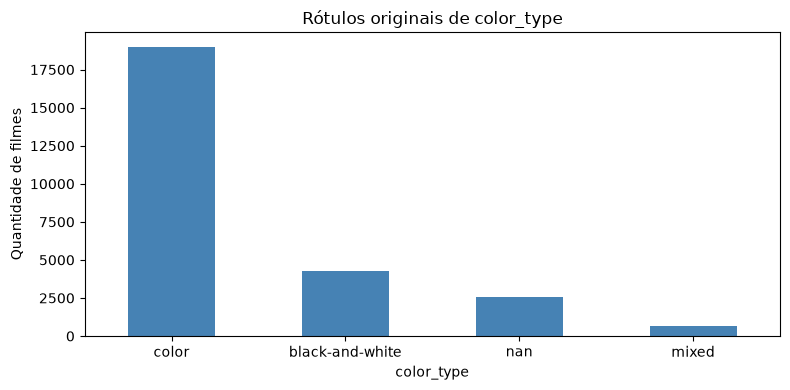

In [5]:
print('Distribuição de color_type na base original:')
print(df['color_type'].value_counts(dropna=False).to_string())

ax = df['color_type'].value_counts(dropna=False).plot(
    kind='bar', figsize=(8, 4), color='steelblue')
ax.set_title('Rótulos originais de color_type')
ax.set_xlabel('color_type')
ax.set_ylabel('Quantidade de filmes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Transformação nas linhas (limpeza dos registros)

Aplicamos filtros **linha a linha**:

- remoção de filmes duplicados por `film_id`;
- manutenção apenas de rótulos não ambíguos (`color` e `black-and-white`), descartando `mixed` e linhas sem rótulo;
- remoção de durações impossíveis (fora de 20 a 300 minutos) e anos fora da faixa 1920–2025 (a base contém valores como 1896 e 2027 e uma duração de 51.420 minutos).

Esses filtros eliminam ruído e valores extremos que prejudicariam o treinamento.

In [6]:
n_antes = len(df)
df_linhas = df.drop_duplicates(subset='film_id').copy()
df_linhas = df_linhas[df_linhas['color_type'].isin(['color', 'black-and-white'])]
df_linhas = df_linhas[df_linhas['runtime_min'].between(20, 300)]
df_linhas = df_linhas[df_linhas['release_year'].between(1920, 2025)]

print(f'Linhas antes das transformações: {n_antes:,}')
print(f'Linhas depois das transformações: {len(df_linhas):,}')
print(f'Linhas removidas: {n_antes - len(df_linhas):,} '
      f'({(n_antes - len(df_linhas)) / n_antes:.1%})')
print('\nDistribuição das classes após a limpeza:')
print(df_linhas['color_type'].value_counts().to_string())

Linhas antes das transformações: 26,545
Linhas depois das transformações: 22,272
Linhas removidas: 4,273 (16.1%)

Distribuição das classes após a limpeza:
color_type
color              18555
black-and-white     3717


## 3. Transformação nas colunas (engenharia de atributos)

Transformações aplicadas **nas colunas**:

- criação do **alvo binário**: `target = 1` para `color` e `0` para `black-and-white`;
- colunas de texto com listas separadas por `|` são convertidas em **contadores** (`n_genres`, `n_directors`, `n_countries`, `n_languages`, `n_companies`);
- criação de `main_genre` (primeiro gênero) e preenchimento de `mpa_rating` ausente com `unknown`;
- criação de `log_budget_usd` e `log_box_office_usd` (`log1p`) para reduzir a assimetria dos valores monetários;
- seleção de preditores: identificadores (`film_id`, `imdb_id`, `tmdb_id`, títulos), datas e a própria coluna `color_type` são **excluídos** para evitar vazamento.

A imputação de valores faltantes, a padronização e a codificação one-hot serão aplicadas **dentro do pipeline**, usando apenas os dados de treino.

In [7]:
df_model = df_linhas.copy()

# Alvo supervisionado (transformação de coluna)
df_model['target'] = df_model['color_type'].map(
    {'black-and-white': 0, 'color': 1}).astype(int)

# Colunas derivadas de listas delimitadas por '|'
def contar_itens(valor):
    if pd.isna(valor) or str(valor).strip() == '':
        return 0
    return str(valor).count('|') + 1

colunas_lista = {
    'genres': 'n_genres',
    'directors': 'n_directors',
    'countries': 'n_countries',
    'original_languages': 'n_languages',
    'production_companies': 'n_companies',
}
for origem, nova in colunas_lista.items():
    df_model[nova] = df_model[origem].map(contar_itens)

df_model['main_genre'] = (df_model['genres'].fillna('')
                          .str.split('|').str[0].replace('', 'unknown'))
df_model['mpa_rating'] = df_model['mpa_rating'].fillna('unknown')
df_model['log_budget_usd'] = np.log1p(df_model['budget_usd'].clip(lower=0))
df_model['log_box_office_usd'] = np.log1p(df_model['box_office_usd'].clip(lower=0))

num_features = [
    'release_year', 'runtime_min', 'aspect_ratio_value',
    'budget_usd', 'box_office_usd', 'log_budget_usd', 'log_box_office_usd',
    'rotten_tomatoes_pct', 'metacritic_score',
    'oscar_wins', 'oscar_nominations', 'n_cast', 'wikipedia_languages',
    'n_genres', 'n_directors', 'n_countries', 'n_languages', 'n_companies',
]
cat_features = ['main_genre', 'mpa_rating']

X = df_model[num_features + cat_features].copy()
y = df_model['target'].copy()

print('Preditores numéricos:', len(num_features), num_features)
print('Preditores categóricos:', cat_features)
print('\nMatriz de características (X):')
display(X.head())
print('Distribuição do alvo (0 = preto-e-branco, 1 = colorido):')
print(y.value_counts().sort_index().to_string())

Preditores numéricos: 18 ['release_year', 'runtime_min', 'aspect_ratio_value', 'budget_usd', 'box_office_usd', 'log_budget_usd', 'log_box_office_usd', 'rotten_tomatoes_pct', 'metacritic_score', 'oscar_wins', 'oscar_nominations', 'n_cast', 'wikipedia_languages', 'n_genres', 'n_directors', 'n_countries', 'n_languages', 'n_companies']
Preditores categóricos: ['main_genre', 'mpa_rating']

Matriz de características (X):


,release_year,runtime_min,aspect_ratio_value,budget_usd,box_office_usd,log_budget_usd,log_box_office_usd,rotten_tomatoes_pct,metacritic_score,oscar_wins,oscar_nominations,n_cast,wikipedia_languages,n_genres,n_directors,n_countries,n_languages,n_companies,main_genre,mpa_rating
0,1931.0,69.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,12,10,2,1,1,1,1,drama film,unknown
1,1969.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,12,14,1,1,1,1,1,Western film,unknown
2,1976.0,75.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,7,12,2,1,2,3,1,horror film,unknown
4,1994.0,102.0,NaN,NaN,NaN,NaN,NaN,100.0,NaN,0,0,8,16,2,1,1,3,0,action film,R
5,2005.0,103.0,NaN,NaN,NaN,NaN,NaN,67.0,NaN,0,0,13,10,2,1,1,1,0,drama film,unknown


Distribuição do alvo (0 = preto-e-branco, 1 = colorido):
target
0     3717
1    18555


## 4. Divisão em treinamento, validação e teste

Divisão estratificada **60% / 20% / 20%**, preservando a proporção das classes em cada subconjunto:

- **treino:** ajuste dos parâmetros do modelo;
- **validação:** conferência durante o desenvolvimento;
- **teste:** avaliação final, com dados nunca vistos pelo modelo.

In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

for nome, X_parte, y_parte in [
    ('Treinamento', X_train, y_train),
    ('Validação  ', X_val, y_val),
    ('Teste      ', X_test, y_test),
]:
    print(f'{nome}: {len(X_parte):>6,} linhas ({len(X_parte)/len(X):>5.1%}) '
          f'| proporção de filmes coloridos: {y_parte.mean():.1%}')

Treinamento: 13,363 linhas (60.0%) | proporção de filmes coloridos: 83.3%
Validação  :  4,454 linhas (20.0%) | proporção de filmes coloridos: 83.3%
Teste      :  4,455 linhas (20.0%) | proporção de filmes coloridos: 83.3%


## 5. Treinamento do modelo

O pipeline conjunto executa, para os atributos numéricos: imputação pela **mediana** e **padronização**; para os categóricos: imputação pelo valor mais frequente e **one-hot encoding**. O classificador é um **RandomForestClassifier** com `class_weight='balanced'` para lidar com a desproporção entre as classes.

In [9]:
preprocessador = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_features),
])

modelo = Pipeline([
    ('preprocess', preprocessador),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=-1,
    )),
])

modelo.fit(X_train, y_train)
print(f'Modelo treinado com {len(X_train):,} amostras e {len(num_features) + len(cat_features)} preditores.')

Modelo treinado com 13,363 amostras e 20 preditores.


## 6. Avaliação do modelo — acurácia e matriz de confusão

Primeiro verificamos o desempenho na **validação**; em seguida, medimos a **acurácia** e apresentamos a **matriz de confusão** no conjunto de **teste**, que é o resultado final do modelo.

In [10]:
y_val_pred = modelo.predict(X_val)
print('DESEMPENHO NA VALIDAÇÃO')
print(f'Acurácia:            {accuracy_score(y_val, y_val_pred):.4f}')
print(f'Acurácia balanceada: {balanced_accuracy_score(y_val, y_val_pred):.4f}')
print('\n', classification_report(
    y_val, y_val_pred, target_names=['black-and-white', 'color'], digits=3))

DESEMPENHO NA VALIDAÇÃO
Acurácia:            0.9228
Acurácia balanceada: 0.9305

                  precision    recall  f1-score   support

black-and-white      0.699     0.942     0.803       743
          color      0.988     0.919     0.952      3711

       accuracy                          0.923      4454
      macro avg      0.843     0.931     0.877      4454
   weighted avg      0.939     0.923     0.927      4454



DESEMPENHO NO TESTE (dados nunca vistos pelo modelo)
Acurácia:            0.9239 (92.39%)
Acurácia balanceada: 0.9307

                  precision    recall  f1-score   support

black-and-white      0.704     0.941     0.805       744
          color      0.987     0.921     0.953      3711

       accuracy                          0.924      4455
      macro avg      0.845     0.931     0.879      4455
   weighted avg      0.940     0.924     0.928      4455



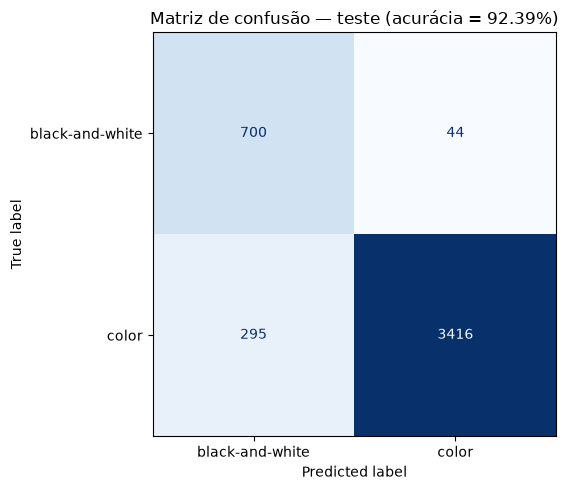

Matriz de confusão (linhas = classe real, colunas = classe prevista):


,previsto: preto-e-branco,previsto: colorido
real: preto-e-branco,700,44
real: colorido,295,3416


In [11]:
y_pred = modelo.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)

print('DESEMPENHO NO TESTE (dados nunca vistos pelo modelo)')
print(f'Acurácia:            {acuracia:.4f} ({acuracia:.2%})')
print(f'Acurácia balanceada: {balanced_accuracy_score(y_test, y_pred):.4f}')
print('\n', classification_report(
    y_test, y_pred, target_names=['black-and-white', 'color'], digits=3))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['black-and-white', 'color'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Matriz de confusão — teste (acurácia = {acuracia:.2%})')
plt.tight_layout()
plt.show()

print('Matriz de confusão (linhas = classe real, colunas = classe prevista):')
display(pd.DataFrame(
    cm,
    index=['real: preto-e-branco', 'real: colorido'],
    columns=['previsto: preto-e-branco', 'previsto: colorido'],
))

## 7. Modelo implantado — predição de novos filmes

Para simular a implantação, o modelo é serializado com `joblib`, recarregado do disco e usado para prever a classe de filmes **novos** (que não participaram do treino nem da avaliação).

In [12]:
caminho_modelo = Path('modelo_final.joblib')
joblib.dump(modelo, caminho_modelo)
modelo_implantado = joblib.load(caminho_modelo)
print(f'Modelo implantado carregado de: {caminho_modelo.resolve()}')

def prever_filme(filme: dict) -> str:
    """Recebe um dicionário com os preditores e retorna a classe prevista."""
    nova_linha = pd.DataFrame([filme])[num_features + cat_features]
    pred = int(modelo_implantado.predict(nova_linha)[0])
    probs = modelo_implantado.predict_proba(nova_linha)[0]
    classes = list(modelo_implantado.named_steps['classifier'].classes_)
    confianca = probs[classes.index(pred)]
    rotulo = {0: 'black-and-white (preto-e-branco)', 1: 'color (colorido)'}[pred]
    print(f'  → Previsão: {rotulo} | confiança estimada: {confianca:.1%}')
    return rotulo

filme_novo_1 = {
    'release_year': 1996, 'runtime_min': 112, 'aspect_ratio_value': 1.85,
    'budget_usd': 25_000_000, 'box_office_usd': 120_000_000,
    'log_budget_usd': np.log1p(25_000_000),
    'log_box_office_usd': np.log1p(120_000_000),
    'rotten_tomatoes_pct': 94.0, 'metacritic_score': 82.0,
    'oscar_wins': 2, 'oscar_nominations': 7, 'n_cast': 28,
    'wikipedia_languages': 35, 'n_genres': 3, 'n_directors': 1,
    'n_countries': 2, 'n_languages': 2, 'n_companies': 3,
    'main_genre': 'drama film', 'mpa_rating': 'R',
}

filme_novo_2 = {
    'release_year': 1943, 'runtime_min': 98, 'aspect_ratio_value': 1.37,
    'budget_usd': 500_000, 'box_office_usd': 2_000_000,
    'log_budget_usd': np.log1p(500_000),
    'log_box_office_usd': np.log1p(2_000_000),
    'rotten_tomatoes_pct': 88.0, 'metacritic_score': 75.0,
    'oscar_wins': 1, 'oscar_nominations': 4, 'n_cast': 15,
    'wikipedia_languages': 22, 'n_genres': 2, 'n_directors': 1,
    'n_countries': 1, 'n_languages': 1, 'n_companies': 1,
    'main_genre': 'drama film', 'mpa_rating': 'unknown',
}

print('Filme novo 1 (lançamento moderno):')
prever_filme(filme_novo_1)
print('\nFilme novo 2 (lançamento antigo):')
prever_filme(filme_novo_2)

Modelo implantado carregado de: C:\Users\Antonio\Documents\Default Project\modelo_final.joblib
Filme novo 1 (lançamento moderno):


  → Previsão: color (colorido) | confiança estimada: 94.1%

Filme novo 2 (lançamento antigo):
  → Previsão: black-and-white (preto-e-branco) | confiança estimada: 91.5%


'black-and-white (preto-e-branco)'

## Resumo dos requisitos atendidos

| Requisito | Onde está no notebook |
|---|---|
| Base de dados do Kaggle indicada | Célula de carregamento (download da API pública + arquivo local em `dados/`) |
| Estatísticas descritivas gerais | Seção 1 (`shape`, `dtypes`, `describe(include='all')`, valores ausentes, distribuição) |
| Transformação em colunas | Seção 3 (alvo binário, contadores derivados de listas, `main_genre`, `log1p`) |
| Transformação em linhas | Seção 2 (deduplicação, remoção de rótulos ambíguos e de valores extremos) |
| Treino, validação e teste | Seção 4 (divisão estratificada 60/20/20) |
| Treinamento e avaliação do modelo | Seções 5 e 6 (pipeline + RandomForest, relatório de classificação) |
| Matriz de confusão e acurácia | Seção 6 (teste) |
| Predição do modelo implantado | Seção 7 (serialização com `joblib`, recarga e previsão de novos filmes) |

**Observação:** a classe `color` é predominante na base; por isso também são informadas a acurácia balanceada e as métricas por classe. Além disso, o ano de lançamento é um preditor muito forte (filmes antigos tendem a ser preto-e-branco), o que deve ser considerado ao interpretar o desempenho.